# 03 — Structure of the targets: repeated buildings and intrinsic dimension

The models plateau because an 8 h curve only partly determines the targets (notebook 02 / the
synthetic-vs-shuffled-label diagnostic). Before changing the modelling, two questions about the
**targets themselves**:

1. **Do buildings repeat?** If the same target vector appears in several simulations (same
   building, different excitation / hidden initial state), we can measure the noise floor
   directly, learn nuisance-invariant representations, and must check the split for leakage.
2. **How many independent quantities do the 6 targets contain?** If they are generated from a
   few building parameters, they lie on a low-dimensional manifold, which constrains the outputs
   and tells us how many numbers the network really has to infer.

Only the targets, the excitation settings and the frozen split are loaded (no series).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from ipe_prediction.data import TARGET_NAMES
from ipe_prediction.eda import plotting as P
from ipe_prediction.eda.loading import load_targets_only

P.set_style()
pd.set_option("display.precision", 4)
torch.manual_seed(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sims = load_targets_only(ROOT / "quentin_house")
Y = sims.targets.double()  # (N, 6) canonical order
N = len(Y)

with np.load(ROOT / "outputs" / "splits" / "split_seed42.npz") as f:
    split_of = np.empty(N, dtype=object)
    for name in ("train", "val", "test"):
        split_of[f[name]] = name
print(f"{N:,} simulations | targets {TARGET_NAMES} | excitation settings {sims.excitation_names}")

1,000,000 simulations | targets ('HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf') | excitation settings ['max_power_wat', 'start_amplitude_wat', 'end_amplitude_wat', 'start_period_hours', 'end_period_hours', 'transition_speed', 'phase_shift', 'average_fluctuation_wat', 'prbs_min_duration_hours', 'prbs_max_duration_hours', 'prbs_probability_on', 'prbs_seed']


## 1. Do buildings repeat?

### 1.1 Exact duplicates of the target vector

In [2]:
unique_rows, inverse, counts = torch.unique(Y, dim=0, return_inverse=True, return_counts=True)
group_size = counts[inverse]  # size of the group each simulation belongs to
print(f"distinct target vectors: {len(unique_rows):,} for {N:,} simulations "
      f"({len(unique_rows) / N:.2%})")
print(f"simulations sharing their target vector with at least one other: {(group_size > 1).float().mean():.2%}")
display(pd.Series(counts.numpy()).value_counts().sort_index().rename("number of groups").to_frame()
        .rename_axis("simulations per target vector").head(15))

distinct target vectors: 1,000,000 for 1,000,000 simulations (100.00%)
simulations sharing their target vector with at least one other: 0.00%


,number of groups
simulations per target vector,
1,1000000


### 1.2 Distinct values per target

A parameter grid (e.g. a few insulation levels) would show up as a small number of distinct values
in some columns, even if the full vectors are unique.

In [3]:
distinct = {n: torch.unique(Y[:, j]).numel() for j, n in enumerate(TARGET_NAMES)}
rounded = {n: torch.unique(Y[:, j].round(decimals=2)).numel() for j, n in enumerate(TARGET_NAMES)}
display(pd.DataFrame({"distinct values": distinct, "distinct at 0.01 resolution": rounded,
                      "min": Y.min(0).values.numpy(), "max": Y.max(0).values.numpy()}, index=TARGET_NAMES))

,distinct values,distinct at 0.01 resolution,min,max
HLC,926439,19225,111.4029,367.9952
HLC_mit,949876,15177,42.8427,231.5326
HLC_ext,935564,10788,52.6465,185.8920
tau_b,945444,7414,20.1987,122.8848
tau_n,932882,1678,5.1720,25.8390
tau_inf,951836,5723,10.4850,93.1187


### 1.3 Near-duplicates: nearest neighbour in target space

Exact equality can miss repeats stored with float noise. For a random sample of simulations we
compute the distance to the nearest *other* simulation in the standardised target space
(heat-loss coefficients in W/K, time constants in log scale). Repeated buildings would give a
spike of near-zero distances; a continuous sampling of buildings gives a smooth distribution.

nearest-neighbour distance quantiles (standardised units):
{0.0: 0.01644, 0.01: 0.03816, 0.1: 0.06451, 0.5: 0.10037, 0.9: 0.16216}
share with a neighbour closer than 1e-3: 0.00%


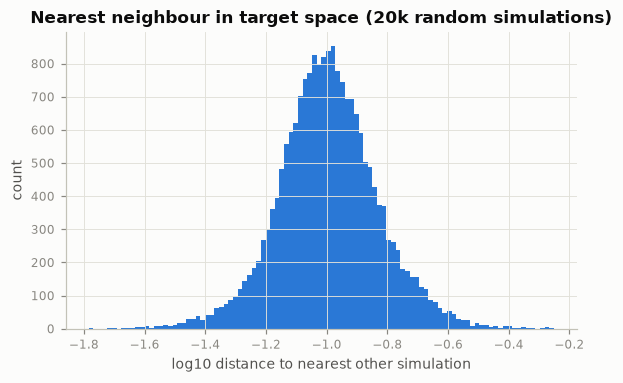

In [4]:
def standardise(y: torch.Tensor) -> torch.Tensor:
    z = torch.cat([y[:, 1:3], y[:, 3:].log()], 1)  # HLC_mit, HLC_ext, log taus (HLC = sum)
    return (z - z.mean(0)) / z.std(0)


Z = standardise(Y).float().to(dev)
query = torch.randperm(N)[:20_000]
nn_dist = []
for chunk in query.split(250):
    d = torch.cdist(Z[chunk.to(dev)], Z)
    d[torch.arange(len(chunk)), chunk.to(dev)] = float("inf")  # exclude self
    nn_dist.append(d.min(1).values.cpu())
nn_dist = torch.cat(nn_dist)
print("nearest-neighbour distance quantiles (standardised units):")
print({q: round(float(nn_dist.quantile(q)), 5) for q in (0.0, 0.01, 0.1, 0.5, 0.9)})
print(f"share with a neighbour closer than 1e-3: {(nn_dist < 1e-3).float().mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(nn_dist.clamp_min(1e-6).log10().numpy(), bins=100)
ax.set(xlabel="log10 distance to nearest other simulation", ylabel="count",
       title="Nearest neighbour in target space (20k random simulations)");

### 1.4 Do repeats cross the train / validation / test split?

In [5]:
repeated = group_size > 1
if repeated.any():
    groups = pd.DataFrame({"group": inverse.numpy(), "split": split_of})[repeated.numpy()]
    splits_per_group = groups.groupby("group")["split"].nunique()
    print(f"repeated groups spanning more than one split: {(splits_per_group > 1).mean():.2%}")
    val_in_train = groups[groups.split == "val"].group.isin(groups[groups.split == "train"].group)
    print(f"validation simulations whose building is also in training: {val_in_train.mean():.2%}")
else:
    print("no repeated target vectors: no building-level leakage across the split")

no repeated target vectors: no building-level leakage across the split


## 2. How many independent quantities do the targets contain?

### 2.1 The additivity constraint

In [6]:
gap = (Y[:, 0] - Y[:, 1] - Y[:, 2]).abs()
print(f"|HLC - (HLC_mit + HLC_ext)|: max {gap.max():.2e} W/K, mean {gap.mean():.2e} W/K "
      f"(HLC itself: {Y[:, 0].mean():.1f} W/K on average)")

|HLC - (HLC_mit + HLC_ext)|: max 2.29e-05 W/K, mean 5.03e-06 W/K (HLC itself: 232.9 W/K on average)


HLC is therefore not an independent quantity. The remaining analysis uses the 5 others:
`HLC_mit`, `HLC_ext` (W/K) and `log tau_b`, `log tau_n`, `log tau_inf`, all standardised.

### 2.2 Linear structure: PCA

In [7]:
names5 = ["HLC_mit", "HLC_ext", "log tau_b", "log tau_n", "log tau_inf"]
Zc = Z.cpu().double()
eigval, eigvec = torch.linalg.eigh(torch.cov(Zc.T))
eigval, eigvec = eigval.flip(0), eigvec.flip(1)
explained = eigval / eigval.sum()
display(pd.DataFrame({"explained variance": explained.numpy(), "cumulative": explained.cumsum(0).numpy()},
                     index=[f"PC{i + 1}" for i in range(5)]))
display(pd.DataFrame(eigvec.numpy(), index=names5, columns=[f"PC{i + 1}" for i in range(5)]).round(3)
        .style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))
display(pd.DataFrame(torch.corrcoef(Zc.T).numpy(), index=names5, columns=names5).round(3))

,explained variance,cumulative
PC1,0.6481,0.6481
PC2,0.2003,0.8484
PC3,0.0966,0.9449
PC4,0.0509,0.9958
PC5,0.0042,1.0000


,PC1,PC2,PC3,PC4,PC5
HLC_mit,-0.354000,0.591000,0.704000,0.158000,0.077000
HLC_ext,-0.257000,-0.807000,0.523000,0.083000,0.050000
log tau_b,0.532000,-0.016000,0.091000,0.525000,0.658000
log tau_n,0.490000,0.022000,0.382000,-0.766000,0.162000
log tau_inf,0.534000,-0.002000,0.277000,0.325000,-0.729000


,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf
HLC_mit,1.000,-0.001,-0.566,-0.449,-0.507
HLC_ext,-0.001,1.000,-0.396,-0.347,-0.368
log tau_b,-0.566,-0.396,1.000,0.762,0.966
log tau_n,-0.449,-0.347,0.762,1.000,0.834
log tau_inf,-0.507,-0.368,0.966,0.834,1.000


### 2.3 Non-linear structure: how well is each target predicted by the others?

k-nearest-neighbour regression (k = 10) of each standardised target from the 4 others, fitted on
200k simulations and scored on 20k different ones. An R² close to 1 means the target is (almost) a
function of the others, i.e. one dimension fewer to infer.

In [8]:
ref = torch.randperm(N)[:200_000]
qry = torch.randperm(N)[:20_000]
qry = qry[~torch.isin(qry, ref)]


def knn_r2(features: list[int], target: int, k: int = 10) -> float:
    xr, xq = Z[ref.to(dev)][:, features], Z[qry.to(dev)][:, features]
    yr, yq = Z[ref.to(dev), target], Z[qry.to(dev), target]
    pred = torch.cat([yr[torch.cdist(c, xr).topk(k, largest=False).indices].mean(1) for c in xq.split(500)])
    return float(1 - (pred - yq).pow(2).mean() / yq.var())


rows = {}
for j, name in enumerate(names5):
    others = [i for i in range(5) if i != j]
    rows[name] = {
        "from the 4 others": knn_r2(others, j),
        "from HLC_mit, HLC_ext": knn_r2([0, 1], j) if j >= 2 else np.nan,
        "from the 2 other taus": knn_r2([i for i in (2, 3, 4) if i != j], j) if j >= 2 else np.nan,
    }
display(pd.DataFrame(rows).T.round(3).rename_axis("R² of"))

,from the 4 others,"from HLC_mit, HLC_ext",from the 2 other taus
R² of,,,
HLC_mit,0.398,NaN,NaN
HLC_ext,0.214,NaN,NaN
log tau_b,0.947,0.425,0.933
log tau_n,0.713,0.250,0.691
log tau_inf,0.956,0.330,0.951


### 2.4 Intrinsic dimension (TwoNN estimator)

The TwoNN estimator (Facco et al., 2017) uses the ratio of the distances to the 2nd and 1st
nearest neighbours: for data on a `d`-dimensional manifold, `d = n / sum(log(r2 / r1))`. It is
robust to curvature and density variations. Reference values: 5 for 5 independent quantities.

In [9]:
def two_nn(x: torch.Tensor) -> float:
    r = []
    for c in x.split(500):
        d = torch.cdist(c, x).topk(3, largest=False).values  # self, 1st, 2nd
        r.append((d[:, 2] / d[:, 1].clamp_min(1e-12)).cpu())
    mu = torch.cat(r).double().clamp_min(1 + 1e-12)
    return float(len(mu) / mu.log().sum())


sample = Z[torch.randperm(N)[:50_000].to(dev)]
dims = {
    "5 targets (HLC_mit, HLC_ext, 3 log taus)": two_nn(sample),
    "HLC_mit, HLC_ext": two_nn(sample[:, :2]),
    "3 log taus": two_nn(sample[:, 2:]),
    "reference: 5 independent Gaussians": two_nn(torch.randn_like(sample)),
}
display(pd.Series(dims, name="estimated intrinsic dimension").round(2).to_frame())

,estimated intrinsic dimension
"5 targets (HLC_mit, HLC_ext, 3 log taus)",4.98
"HLC_mit, HLC_ext",1.92
3 log taus,2.99
reference: 5 independent Gaussians,5.04


## 3. Findings

**1. Buildings do not repeat.** All 1,000,000 target vectors are distinct, and no two simulations
are closer than 0.016 standardised units in target space (median nearest-neighbour distance 0.10).
The building parameters were sampled continuously, once per simulation. Consequences:

* no same-building pairs: no direct measurement of the noise floor from repeats, and no
  "same building, different nuisance" contrastive training;
* no building-level leakage: the per-simulation split is clean;
* every simulation is a new building with a new hidden initial state, so the model must infer the
  building from a single 8 h test, which is the realistic setting.

**2. HLC is exactly `HLC_mit + HLC_ext`** (max gap 2e-5 W/K), as enforced by the models.

**3. The 5 remaining targets are 5 independent quantities, with a strong "inertia" structure.**

* `HLC_mit` and `HLC_ext` are uncorrelated (r = -0.001): they were sampled independently, so their
  split must come from the curve itself, not from a population prior.
* The three time constants are strongly linked: `log tau_inf` is predicted at R² = 0.95 by the two
  other taus, `log tau_b` at 0.93, `log tau_n` only at 0.69. PCA: 4 components explain 99.6 % of
  the variance; the 5th (0.4 %) is the small part of the taus not shared.
* The taus are negatively correlated with both heat-loss coefficients (r ≈ -0.35 to -0.57), as
  expected from `tau ~ C / H`: a building that loses heat faster has shorter time constants.
* The TwoNN estimate is still about 5 (1.9 for the two heat-loss coefficients, 3.0 for the
  taus): locally, all 5 quantities vary independently. They are not a function of fewer
  parameters, but the taus mostly move together along one direction.

**What this means for the modelling.**

* There is no hidden discrete structure to exploit: the task is a continuous regression of 5
  quantities from one test, and its ceiling is set by the information in the curve.
* Errors on `tau_b` and `tau_inf` are tied to the error on the shared "inertia" factor (and on
  HLC through `tau ~ C / H`). Predicting the targets jointly, ideally with a joint uncertainty,
  fits this structure better than 6 independent outputs.
* The independent `HLC_mit` / `HLC_ext` split is the part that needs the most information from
  the curve. It is the natural focus for the identifiability analysis (canonical correlations
  between the curve embedding and the targets, idea B4).